In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Deteksi otomatis folder utama proyek ("Data Mining-SPK")
current_dir = Path.cwd()
BASE_DIR = current_dir.parent if current_dir.name == "Notebooks" else current_dir

DATA_DIR = BASE_DIR / "Data"
CLEAN_DIR = DATA_DIR / "Clean"
RAW_PATH = DATA_DIR / "Raw" / "data_responden.csv"

# Load hasil clustering & matriks centroid alternatif dari proses sebelumnya
clustered = pd.read_csv(CLEAN_DIR / "hasil_clustering_kmeans.csv")
centroid_spk = pd.read_csv(CLEAN_DIR / "centroid_alternatif_spk.csv", index_col=0)

print("Data berhasil dimuat! Total responden terevaluasi:", len(clustered))
display(centroid_spk)

Data berhasil dimuat! Total responden terevaluasi: 37


,C1_Jasmani,C2_Mental,C3_Pola_Belajar,C4_Akademik
A1 (Cluster 1),3.200,3.040,3.113,4.383
A2 (Cluster 2),2.000,1.533,2.125,4.319
A3 (Cluster 3),3.075,2.625,1.950,4.328


## Evaluasi Teknis Kualitas Cluster (Silhouette Score & Davies-Bouldin Index)

Mengukur seberapa rapat anggota di dalam satu cluster dan seberapa jelas pemisahan antar-cluster.

In [2]:
features = ["C1_Jasmani", "C2_Mental", "C3_Pola_Belajar"]
X_scaled = StandardScaler().fit_transform(clustered[features])
labels = clustered["Cluster"]

sil_score = silhouette_score(X_scaled, labels)
db_score = davies_bouldin_score(X_scaled, labels)

eval_metrics = pd.DataFrame({
    "Metrik Evaluasi": ["Silhouette Score", "Davies-Bouldin Index (DBI)"],
    "Nilai": [round(sil_score, 4), round(db_score, 4)],
    "Interpretasi Standar": [
        "Rentang -1 s.d. 1 (Semakin mendekati 1 semakin terpisah jelas)",
        "Nilai >= 0 (Semakin mendekati 0 semakin baik / rendah kemiripan antar-cluster)"
    ]
})

print("=== EVALUASI TEKNIS KUALITAS CLUSTER (K-MEANS) ===")
display(eval_metrics)

=== EVALUASI TEKNIS KUALITAS CLUSTER (K-MEANS) ===


,Metrik Evaluasi,Nilai,Interpretasi Standar
0,Silhouette Score,0.2794,Rentang -1 s.d. 1 (Semakin mendekati 1 semakin...
1,Davies-Bouldin Index (DBI),1.1779,Nilai >= 0 (Semakin mendekati 0 semakin baik /...


## Evaluasi Bisnis & Validasi Domain (Profil Cluster & Korelasi ke IPK / $C_4$)

Mengecek sebaran responden tiap cluster, memberikan label profil bisnis, serta membuktikan korelasi gaya hidup terhadap performa akademik ($C_4$).

=== RINGKASAN PROFIL & VALIDASI DOMAIN PER CLUSTER ===


,Jumlah_Responden,Persentase,Mean_C1_Jasmani,Mean_C2_Mental,Mean_C3_Pola_Belajar,Mean_C4_Akademik
Cluster,,,,,,
1,15,40.5,3.200,3.040,3.113,4.383
2,6,16.2,2.000,1.533,2.125,4.319
3,16,43.2,3.075,2.625,1.950,4.328



=== KORELASI KRITERIA GAYA HIDUP TERHADAP C4 AKADEMIK ===


,C4_Akademik
C1_Jasmani,0.018
C2_Mental,0.200
C3_Pola_Belajar,0.146
C4_Akademik,1.000


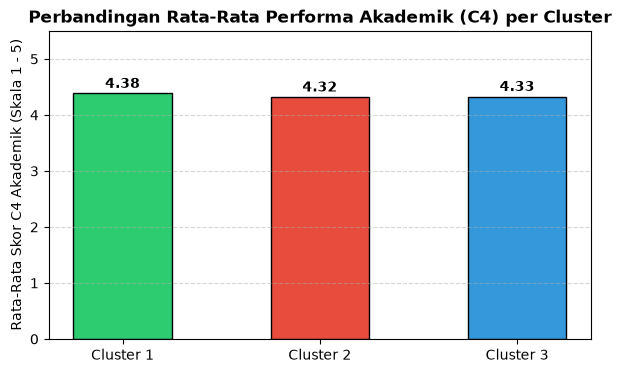

In [3]:
# 1. Sebaran dan Rata-rata Profil per Cluster (Cluster Profiling)
profil_summary = clustered.groupby("Cluster").agg(
    Jumlah_Responden=("C1_Jasmani", "count"),
    Persentase=("C1_Jasmani", lambda x: round(len(x) / len(clustered) * 100, 1)),
    Mean_C1_Jasmani=("C1_Jasmani", "mean"),
    Mean_C2_Mental=("C2_Mental", "mean"),
    Mean_C3_Pola_Belajar=("C3_Pola_Belajar", "mean"),
    Mean_C4_Akademik=("C4_Akademik", "mean")
).round(3)

print("=== RINGKASAN PROFIL & VALIDASI DOMAIN PER CLUSTER ===")
display(profil_summary)

# 2. Uji Korelasi Pearson (Hubungan Gaya Hidup C1-C3 terhadap Performa Akademik C4)
corr_matrix = clustered[["C1_Jasmani", "C2_Mental", "C3_Pola_Belajar", "C4_Akademik"]].corr()

print("\n=== KORELASI KRITERIA GAYA HIDUP TERHADAP C4 AKADEMIK ===")
display(corr_matrix[["C4_Akademik"]].round(3))

# 3. Visualisasi Perbandingan Rata-rata Performa Akademik (C4) antar Cluster
plt.figure(figsize=(7, 4))
bars = plt.bar(
    [f"Cluster {i}" for i in profil_summary.index],
    profil_summary["Mean_C4_Akademik"],
    color=["#2ecc71", "#e74c3c", "#3498db"],
    edgecolor="black",
    width=0.5
)
plt.title("Perbandingan Rata-Rata Performa Akademik (C4) per Cluster", fontweight="bold")
plt.ylabel("Rata-Rata Skor C4 Akademik (Skala 1 - 5)")
plt.ylim(0, 5.5)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f"{yval:.2f}", ha="center", fontweight="bold")

plt.show()

## Sensitivity Analysis SPK SAW (Uji Stabilitas Bobot)

Menguji apakah peringkat alternatif terbaik tetap konsisten ketika bobot kriteria ($W$) diubah-ubah dalam berbagai skenario.

In [4]:
# Ambil bobot asli hasil survei dari data_responden.csv
df_raw = pd.read_csv(RAW_PATH)
df_raw.columns = [str(c).strip() for c in df_raw.columns]
if "Timestamp" in df_raw.columns:
    df_raw = df_raw[df_raw["Timestamp"].notna()].copy()
df_raw = df_raw.drop_duplicates().copy()

def find_col(df_target, fragment):
    return [c for c in df_target.columns if fragment.lower() in c.lower()][0]

imp_df = pd.DataFrame({
    "C1_Jasmani": pd.to_numeric(df_raw[find_col(df_raw, "penting gaya hidup sehat")], errors="coerce"),
    "C2_Mental": pd.to_numeric(df_raw[find_col(df_raw, "penting kondisi mental")], errors="coerce"),
    "C3_Pola_Belajar": pd.to_numeric(df_raw[find_col(df_raw, "penting pola belajar")], errors="coerce"),
    "C4_Akademik": pd.to_numeric(df_raw[find_col(df_raw, "penting performa akademik")], errors="coerce")
})
bobot_survei = (imp_df.mean() / imp_df.mean().sum()).to_dict()

# Fungsi kalkulasi SAW
def evaluasi_saw(matriks_alt, bobot_dict, nama_skenario):
    w = pd.Series(bobot_dict)
    w = w / w.sum()
    norm = matriks_alt[w.index].divide(matriks_alt[w.index].max(axis=0), axis=1)
    skor = norm.mul(w, axis=1).sum(axis=1)
    return pd.DataFrame({
        f"Skor ({nama_skenario})": skor.round(4),
        f"Rank ({nama_skenario})": skor.rank(ascending=False).astype(int)
    })

# Definisikan 4 skenario bobot untuk uji sensitivitas
skenario_1 = evaluasi_saw(centroid_spk, bobot_survei, "Survei Asli")
skenario_2 = evaluasi_saw(centroid_spk, {"C1_Jasmani": 0.25, "C2_Mental": 0.25, "C3_Pola_Belajar": 0.25, "C4_Akademik": 0.25}, "Sama Rata")
skenario_3 = evaluasi_saw(centroid_spk, {"C1_Jasmani": 0.35, "C2_Mental": 0.35, "C3_Pola_Belajar": 0.15, "C4_Akademik": 0.15}, "Fokus Kesehatan")
skenario_4 = evaluasi_saw(centroid_spk, {"C1_Jasmani": 0.15, "C2_Mental": 0.15, "C3_Pola_Belajar": 0.35, "C4_Akademik": 0.35}, "Fokus Akademik")

hasil_sensitivitas = pd.concat([skenario_1, skenario_2, skenario_3, skenario_4], axis=1)

print("=== HASIL SENSITIVITY ANALYSIS SPK SAW (4 SKENARIO BOBOT) ===")
display(hasil_sensitivitas)

=== HASIL SENSITIVITY ANALYSIS SPK SAW (4 SKENARIO BOBOT) ===


,Skor (Survei Asli),Rank (Survei Asli),Skor (Sama Rata),Rank (Sama Rata),Skor (Fokus Kesehatan),Rank (Fokus Kesehatan),Skor (Fokus Akademik),Rank (Fokus Akademik)
A1 (Cluster 1),1.0000,1,1.0000,1,1.0000,1,1.0000,1
A2 (Cluster 2),0.6982,3,0.6993,3,0.6454,3,0.7532,3
A3 (Cluster 3),0.8595,2,0.8596,2,0.8806,2,0.8385,2


## Menyimpan Ringkasan Hasil Evaluasi ke Folder Data/Clean

In [5]:
profil_summary.to_csv(CLEAN_DIR / "evaluasi_profil_cluster.csv", index=True)
hasil_sensitivitas.to_csv(CLEAN_DIR / "evaluasi_sensitivitas_saw.csv", index=True)

print("File evaluasi berhasil disimpan di:")
print("->", CLEAN_DIR / "evaluasi_profil_cluster.csv")
print("->", CLEAN_DIR / "evaluasi_sensitivitas_saw.csv")

File evaluasi berhasil disimpan di:
-> c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean\evaluasi_profil_cluster.csv
-> c:\Users\daniel\Desktop\Data Mining-SPK\Data\Clean\evaluasi_sensitivitas_saw.csv
